# Modeling: naive baseline vs. ridge vs. gradient boosting

Train and compare models that predict **SBP** and **DBP** from the 14 PPG features
built in `ppg_feature_extraction.ipynb`.

Pipeline, using the shared code in `../src/`:

1. Load `data/ppg_features.csv`.
2. Split into train/test **by whole recording** (`src/data_split.py`) — a recording's
   windows never end up split across train and test.
3. Compute the **naive baseline**: always predict the training mean (`src/baseline.py`).
4. Fit **Ridge** (scaled features) and **gradient boosting** for SBP and DBP separately
   (`src/models.py`).
5. Compare all three with MAE/RMSE on the held-out test recordings.
6. Explain predictions with **ridge coefficients** and **GBM permutation importance**
   (`src/importance.py`).

Run this notebook from `notebooks/`, after `preprocess.ipynb` and
`ppg_feature_extraction.ipynb` have produced `data/ppg_features.csv`.

## Setup

Add the repo root to the path so we can import the shared `src/` modules.

In [1]:
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path('..').resolve()))

from src.data_split import grouped_train_test_split, split_summary
from src.baseline import compute_naive_baseline, evaluate_naive_baseline
from src.models import FEATURE_COLUMNS, train_and_compare
from src.importance import importance_report

results_dir = Path('../results')
graphs_dir = results_dir / 'graphs'
graphs_dir.mkdir(parents=True, exist_ok=True)

TARGET_COLS = ('sbp', 'dbp')
RANDOM_STATE = 42

## 1. Load the feature table

One row per usable 5-second window: 14 PPG features, SBP/DBP labels, and source IDs
(`file`, `record_index`, `start_sample`) used to keep recordings intact during splitting.

In [2]:
df = pd.read_csv('../data/ppg_features.csv')
assert set(FEATURE_COLUMNS).issubset(df.columns)
assert set(TARGET_COLS).issubset(df.columns)
print(f'Loaded {len(df):,} rows, {df["file"].nunique()} source file(s), '
      f'{df[["file", "record_index"]].drop_duplicates().shape[0]:,} recordings.')
df.head()

Loaded 527,467 rows, 4 source file(s), 11,989 recordings.


,file,record_index,start_sample,inband_power_ratio,sbp,dbp,heart_rate_bpm,beat_interval_std_ms,pulse_height,rise_time_s,...,rise_fall_ratio,pulse_width_s,max_upslope,ppg_std,ppg_min,ppg_max,ppg_range,ppg_skewness,ppg_kurtosis,n_beats
0,Part_1.mat,0,0,0.988807,121.841618,67.185065,121.841155,6.651835,1.817359,0.139000,...,0.395105,0.172000,22.566971,0.603994,-1.015477,1.244404,2.259881,0.515651,-1.049128,8
1,Part_1.mat,0,625,0.986258,124.747842,68.967875,124.309392,3.771236,1.841432,0.141000,...,0.413552,0.173000,22.546255,0.603707,-0.828494,1.295174,2.123667,0.537671,-1.051481,8
2,Part_1.mat,0,1250,0.983730,125.846835,69.773803,123.966942,7.375636,1.856541,0.143111,...,0.418236,0.175111,22.574495,0.640492,-0.888280,1.567517,2.455796,0.498770,-1.004504,9
3,Part_1.mat,0,1875,0.989113,122.354481,67.111799,123.175182,6.999118,1.845592,0.138000,...,0.394474,0.170000,22.876972,0.652981,-1.261017,1.316331,2.577348,0.366763,-0.960664,8
4,Part_1.mat,0,2500,0.985247,125.578192,69.212096,124.309392,5.333333,1.879927,0.139000,...,0.405369,0.172000,23.149713,0.606510,-0.843065,1.166942,2.010007,0.537381,-1.074263,8


## 2. Split by recording

80/20 train/test split, keeping each recording's windows entirely in one split.
`stratify_col='file'` (the default) keeps Part_1-4 represented in similar proportions
in both splits.

In [3]:
train_df, test_df = grouped_train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
split_summary(train_df, test_df)

,split,rows,recordings
0,train,420509,9589
1,test,106958,2400


## 3. Naive baseline

Always predict the training set's mean SBP/DBP, ignoring every feature. This is the
floor both real models need to beat.

In [4]:
baseline_values = compute_naive_baseline(train_df, TARGET_COLS)
baseline_results = evaluate_naive_baseline(baseline_values, test_df, TARGET_COLS)
print('Naive baseline (train-set mean):', baseline_values)
baseline_results.round(3)

Naive baseline (train-set mean): {'sbp': 128.8815851719202, 'dbp': 68.05336274194222}


,target,predicted_value,mae,rmse
0,sbp,128.882,18.545,22.809
1,dbp,68.053,9.151,11.985


## 4. Ridge and gradient boosting

One model per target per type (4 models total). Ridge gets its 14 features
standardized first; gradient boosting (`HistGradientBoostingRegressor`) uses the raw
features. Both are scored with the same MAE/RMSE function as the baseline above.

In [5]:
results, fitted_models = train_and_compare(
    train_df, test_df, target_cols=TARGET_COLS, random_state=RANDOM_STATE,
)
results.round(3)

,target,model,mae,rmse
0,sbp,naive_baseline,18.545,22.809
1,sbp,ridge,17.748,22.097
2,sbp,gbm,15.544,19.910
3,dbp,naive_baseline,9.151,11.985
4,dbp,ridge,8.826,11.724
5,dbp,gbm,7.940,10.880


## 5. Compare the three models

For each target, how much do ridge and gradient boosting improve on the naive
baseline?

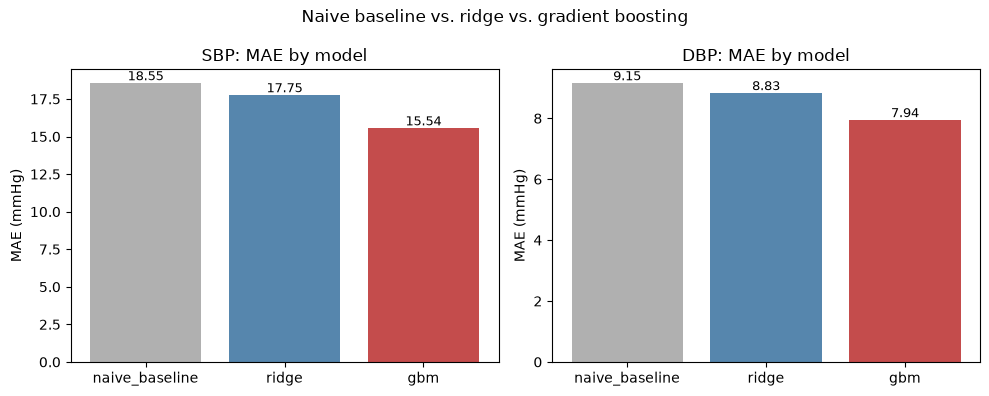

In [6]:
import matplotlib.pyplot as plt

model_order = ['naive_baseline', 'ridge', 'gbm']
colors = {'naive_baseline': '#b0b0b0', 'ridge': '#5686ad', 'gbm': '#c44c4c'}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for ax, target in zip(axes, TARGET_COLS):
    subset = results[results['target'] == target].set_index('model').loc[model_order]
    ax.bar(model_order, subset['mae'], color=[colors[m] for m in model_order])
    ax.set_title(f'{target.upper()}: MAE by model')
    ax.set_ylabel('MAE (mmHg)')
    for i, value in enumerate(subset['mae']):
        ax.text(i, value, f'{value:.2f}', ha='center', va='bottom', fontsize=9)
fig.suptitle('Naive baseline vs. ridge vs. gradient boosting')
fig.tight_layout()
fig.savefig(graphs_dir / 'model_comparison.png', dpi=150)
plt.show()
plt.close(fig)

## 6. Feature importance

- **Ridge**: standardized coefficients — size is directly comparable across all 14
  features; sign shows direction.
- **Gradient boosting**: permutation importance on the *test* split, not the model's
  built-in `feature_importances_` (which can be misleading with correlated features
  like `rise_time_s`/`fall_time_s`/`rise_fall_ratio`).

In [7]:
importance = importance_report(fitted_models, test_df, target_cols=TARGET_COLS)
for target in TARGET_COLS:
    print(f'--- {target.upper()} ---')
    display(importance[importance['target'] == target].drop(columns='target').round(3))

--- SBP ---


,feature,coefficient,abs_coefficient,importance_mean,importance_std
0,pulse_height,-17.941,17.941,1.777,0.009
1,max_upslope,11.384,11.384,2.950,0.021
2,ppg_std,8.332,8.332,1.267,0.012
3,heart_rate_bpm,-4.192,4.192,0.584,0.008
4,rise_fall_ratio,-3.972,3.972,0.513,0.006
5,ppg_kurtosis,-3.760,3.760,0.419,0.010
6,ppg_min,-3.183,3.183,0.078,0.003
7,fall_time_s,-2.269,2.269,0.556,0.009
8,ppg_skewness,1.878,1.878,0.577,0.005
9,ppg_max,-1.852,1.852,0.268,0.004


--- DBP ---


,feature,coefficient,abs_coefficient,importance_mean,importance_std
14,pulse_height,-8.914,8.914,1.177,0.010
15,max_upslope,6.871,6.871,2.056,0.016
16,ppg_std,2.011,2.011,0.218,0.003
17,pulse_width_s,1.808,1.808,0.521,0.007
18,rise_time_s,1.646,1.646,0.374,0.005
19,heart_rate_bpm,1.283,1.283,0.396,0.005
20,ppg_min,-1.033,1.033,0.024,0.001
21,ppg_kurtosis,-0.985,0.985,0.187,0.004
22,rise_fall_ratio,-0.895,0.895,0.509,0.006
23,fall_time_s,0.571,0.571,0.145,0.003


## 7. Visualize feature importance

Ridge coefficients and GBM permutation importance, side by side, per target.

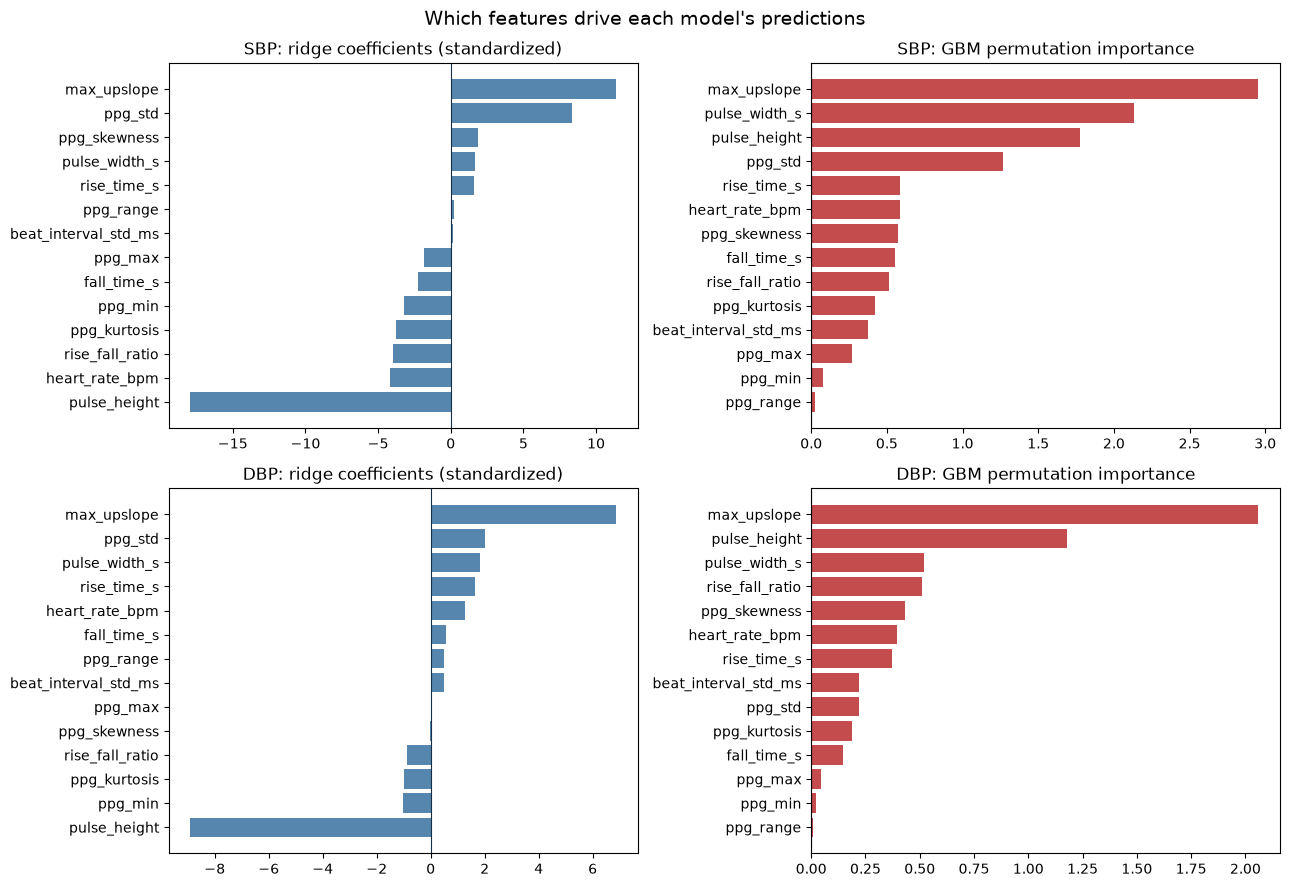

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, target in enumerate(TARGET_COLS):
    subset = importance[importance['target'] == target].set_index('feature')

    ax = axes[row, 0]
    ordered = subset.sort_values('coefficient')
    ax.barh(ordered.index, ordered['coefficient'], color='#5686ad')
    ax.set_title(f'{target.upper()}: ridge coefficients (standardized)')
    ax.axvline(0, color='#183047', linewidth=0.8)

    ax = axes[row, 1]
    ordered = subset.sort_values('importance_mean')
    ax.barh(ordered.index, ordered['importance_mean'], color='#c44c4c')
    ax.set_title(f'{target.upper()}: GBM permutation importance')
    ax.axvline(0, color='#183047', linewidth=0.8)

fig.suptitle('Which features drive each model\'s predictions', fontsize=14)
fig.tight_layout()
fig.savefig(graphs_dir / 'feature_importance.png', dpi=150)
plt.show()
plt.close(fig)

## Notes

- All metrics are computed on recordings the models never trained on — see
  `src/data_split.py` for how that's enforced.
- Ridge and GBM being close to the naive baseline (rather than far below it) would
  match the weak single-feature correlations already seen in
  `ppg_feature_extraction.ipynb` (best |r| &asymp; 0.16 for SBP, &asymp; 0.09 for DBP).
  That's an expected, honest result for this feature set — not necessarily a bug.
- Next steps if these results look weak: try more/different PPG features, tune GBM's
  `max_depth`/`learning_rate`, or try a longer window length.